# Task 1.2: choose the memory and buffer cutoffs together

Use the same grid slices for time-resolved sweeps and scalar convergence:
- Hold the largest buffer cutoff, $N_b=14$, and vary $N_a$.
- Hold the largest memory cutoff, $N_a=40$, and vary $N_b$.

Color gradients identify the varied cutoff. Holding the other mode at its largest cutoff isolates each mode’s truncation effect.

Then compare **every pair on a 6 by 6 grid** with the largest grid pair, $(40,14)$, called the **reference**. The reference is a finite numerical calculation, not an exact state.

KL divergence of photon-number distributions is possible, but it misses coherence and can be singular when a reference probability is zero. We instead compare the entire reduced memory density matrix with **trace distance**:

$$D(t)=\tfrac12\|\rho_a^{(N_a,N_b)}(t)-\rho_a^{(40,14)}(t)\|_1.$$

Embed each smaller state into the reference Fock space with zeros. Do not cut down or renormalize the reference. Record the maximum over **301 saved times from 0 to 3 µs**, including the inflation transient. A distance of 0.01 means at most a one-percentage-point difference in any memory measurement probability (up to solver error).

The single map shows maximum trace distance, with a black **1% threshold** contour. Small circles mark computed pairs; a shape-preserving interpolant smooths the background and contour. Selecting a pair additionally requires **0.5% relative peak-photon error**, **0.1% steady-photon error** and **less than 0.1% population in the highest two memory / highest buffer levels**, for it and all tested pairs with both cutoffs at least as large. Of those pairs, choose the smallest $N_aN_b$.

The notebook loads saved results by default. Set `RERUN=True` to recompute the grid. Raw reduced-state trajectories are cached with a key containing the physical parameters, solver settings, library versions and model source hash. The delivered JSON and compact NPZ contain the derived comparisons and observable curves; raw caches are excluded from Git.


In [1]:
import sys, json, io
from pathlib import Path
from contextlib import redirect_stdout
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures' / f'{name}.png'), width=w))
load = lambda name: json.loads((ROOT / 'results' / f'{name}.json').read_text())


In [2]:
RERUN = False
if RERUN:
    from tasks import task_1_2
    with redirect_stdout(io.StringIO()):
        task_1_2.main()
r = load('task_1_2')

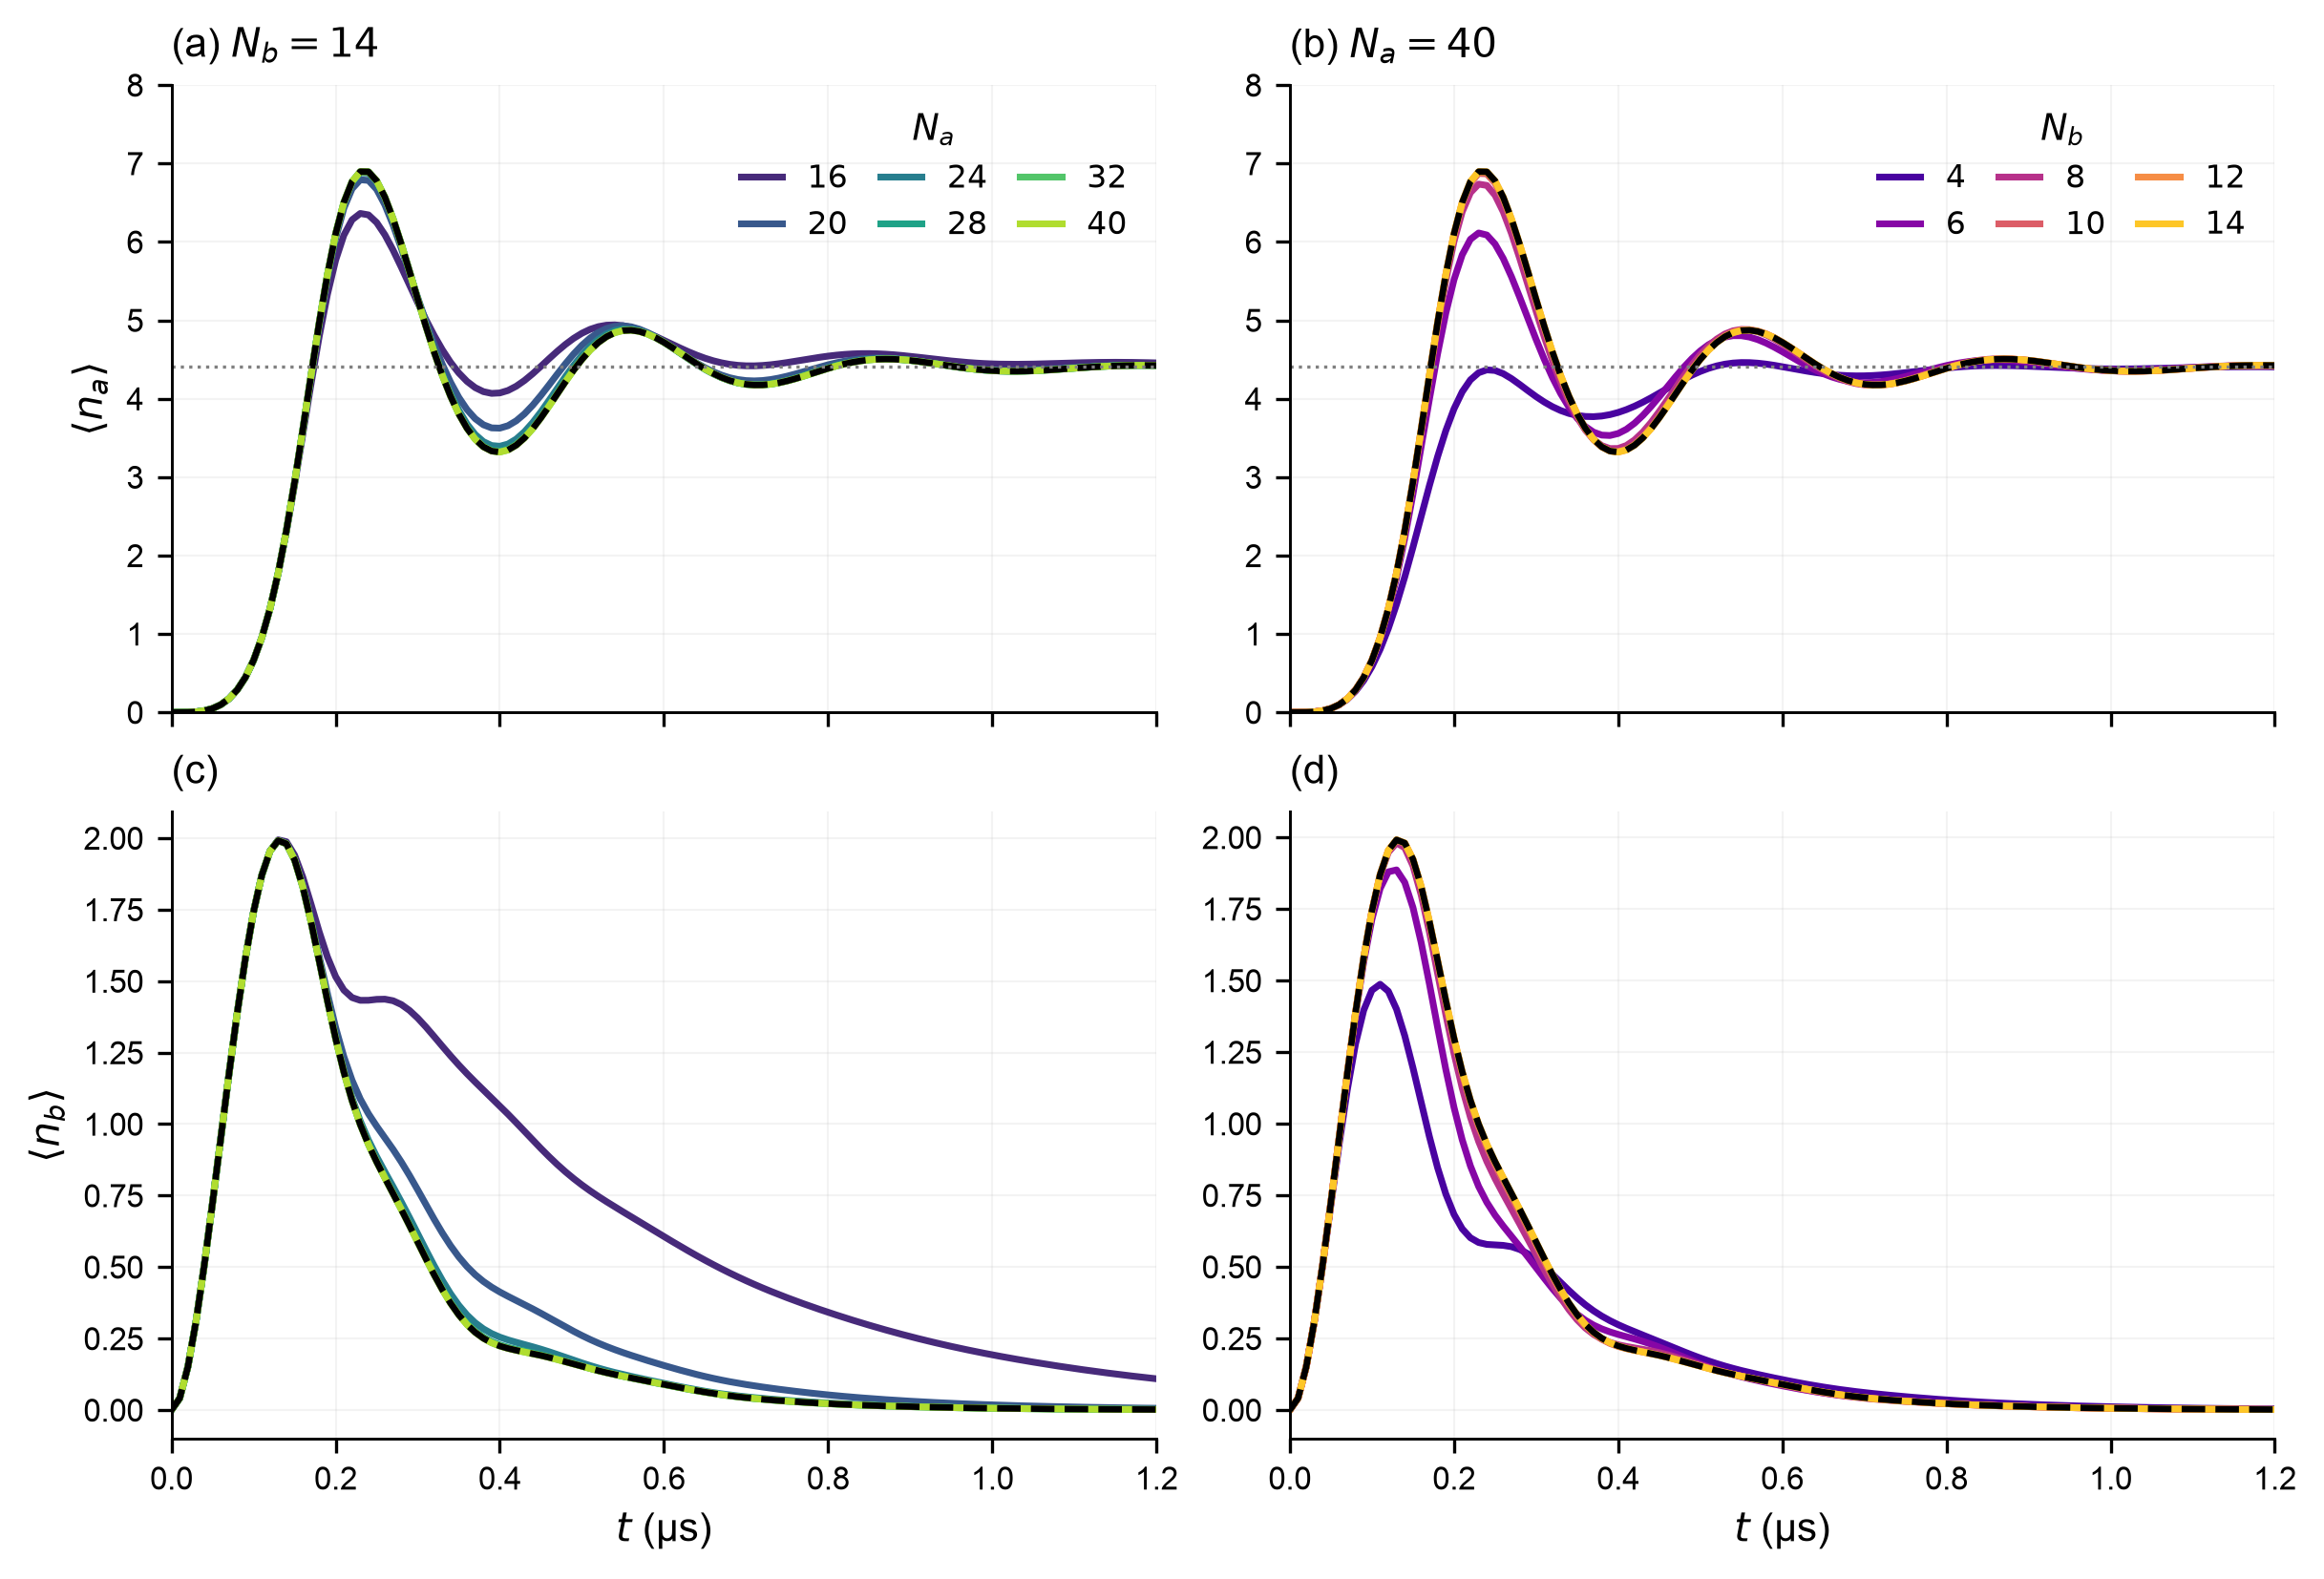

In [3]:
show('task_1_2_cutoff_sweeps', 1050)

**Separate memory and buffer cutoff sweeps.** (a,c) Vary $N_a$ at fixed $N_b=14$; (b,d) vary $N_b$ at fixed $N_a=40$. Color gradients identify the varied cutoff. Upper and lower rows show memory and buffer occupations, respectively. Black dashed curves give the $(40,14)$ reference; horizontal dotted lines mark $\alpha^2$. Only the first $1.2$ µs of each $3$ µs vacuum-inflation trajectory is shown. These are the same grid slices used for the peak and steady-occupation convergence plot.

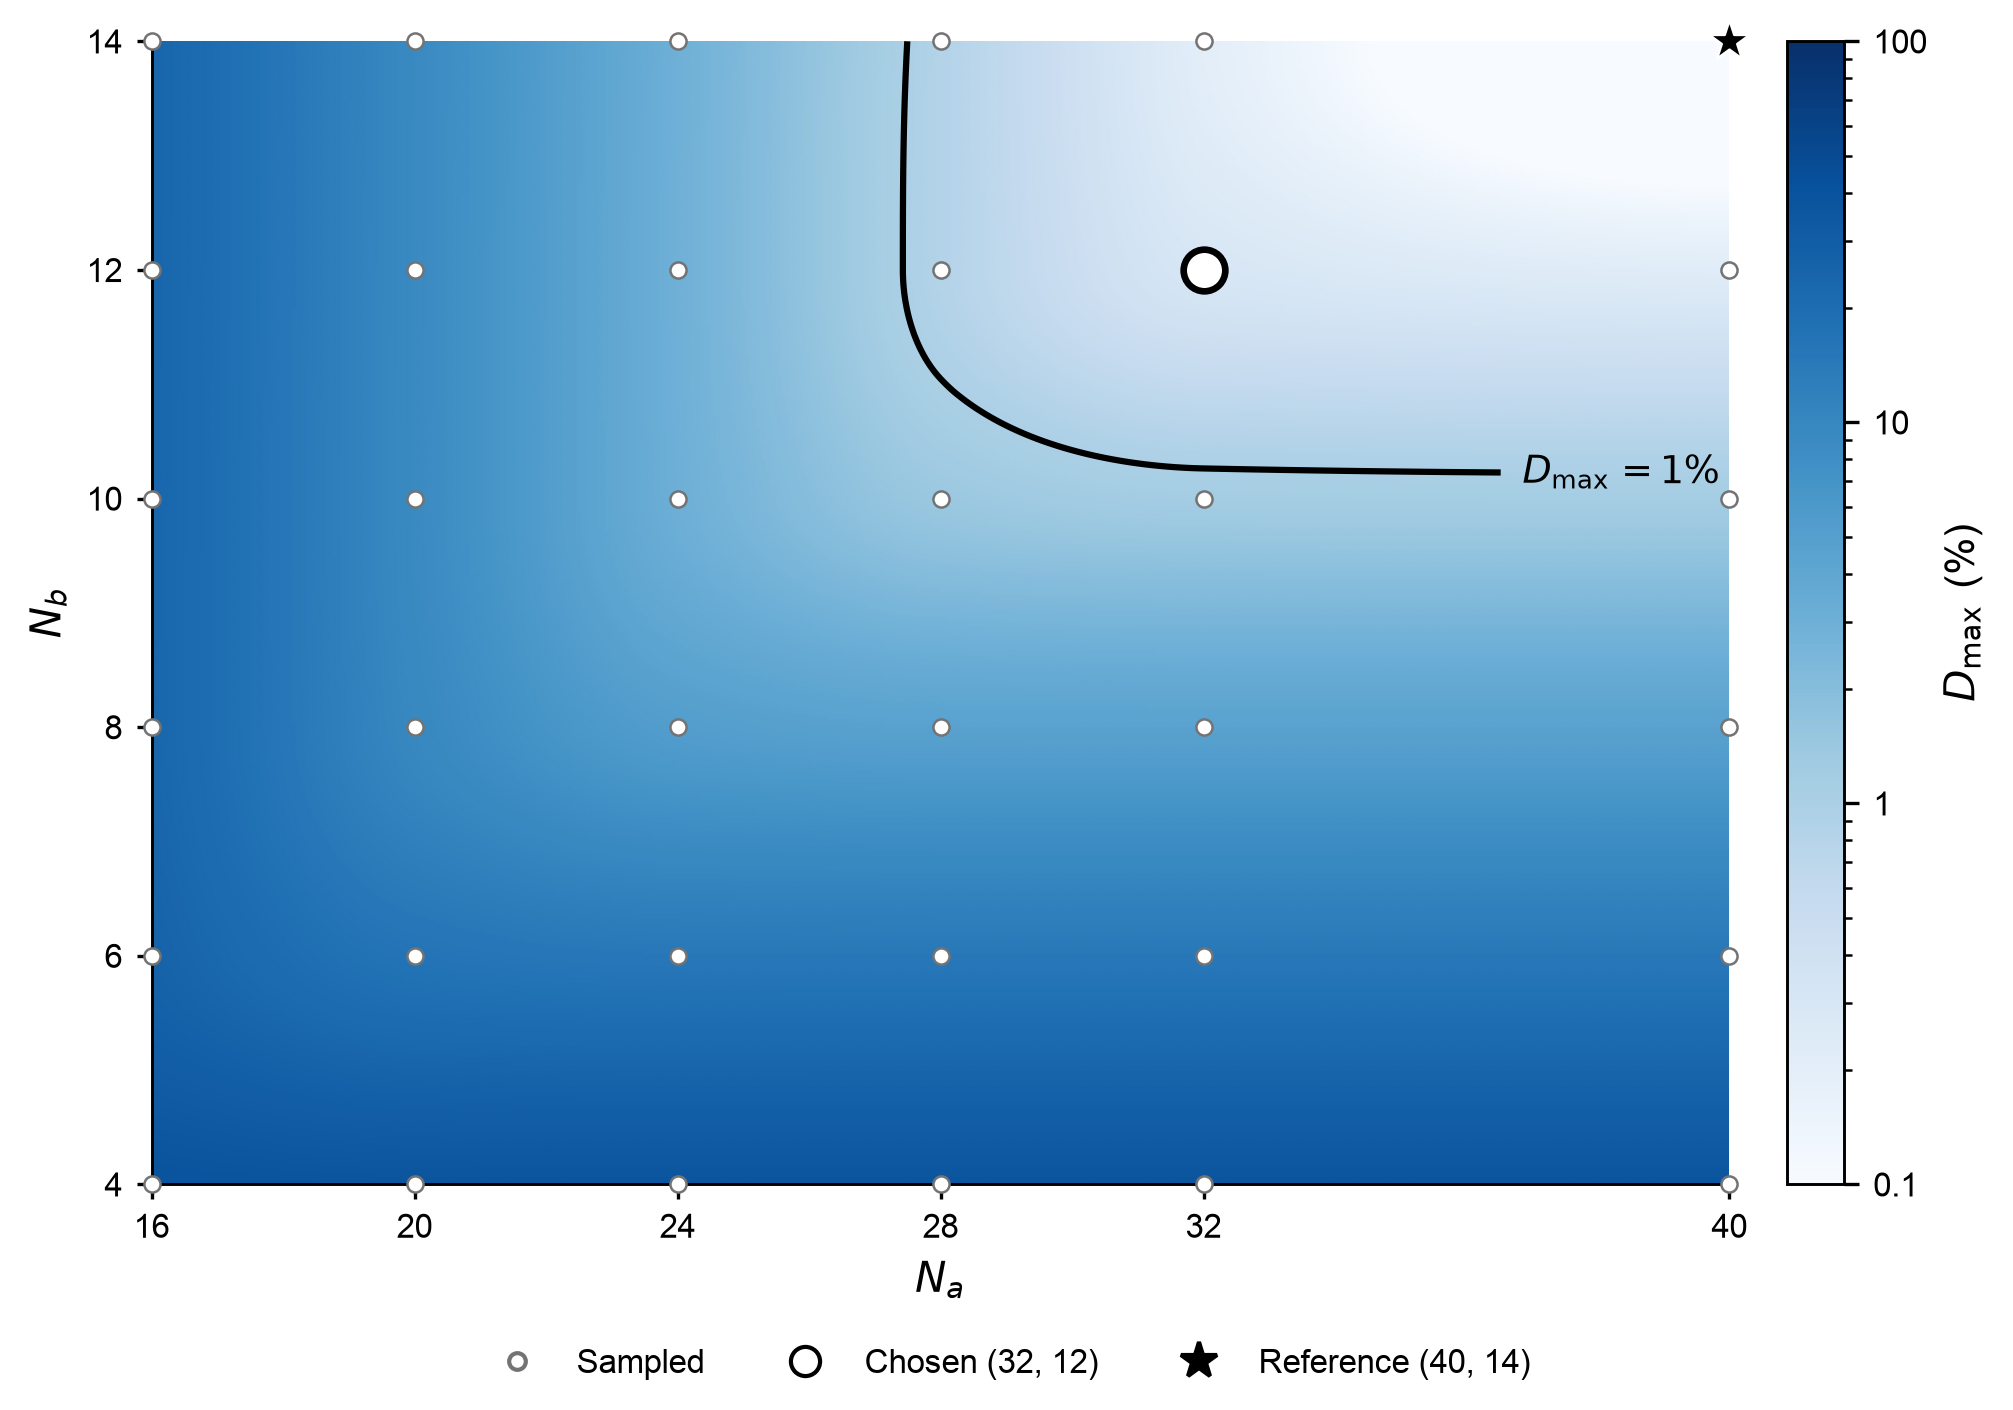

In [4]:
show('task_1_2_error_grid', 1100)

**Joint memory-state convergence.** Axes give the retained memory and buffer dimensions $N_a$ and $N_b$. Blue shading shows $D_{\max}=\max_t\tfrac12\|\rho_a(t)-\rho_{a,\mathrm{ref}}(t)\|_1$ relative to $(40,14)$, where $\rho_a$ is the reduced memory state and smaller states are zero-padded. Lighter shades mean smaller differences; the color bar is logarithmic in percent, with a 0.1% display floor. Small circles mark the 36 computed pairs. The black curve is the **$D_{\max}=1\%$ threshold**; the upper-right side satisfies the state-distance criterion. The black ring marks the chosen cutoff $(32,12)$, used throughout Tasks 1.1 and 1.3; the star marks reference $(40,14)$, where $D_{\max}=0$. Background and contour use the same shape-preserving interpolation; cutoff checks use computed values. Each distance is maximized over 301 saved times from 0 to 3 µs.

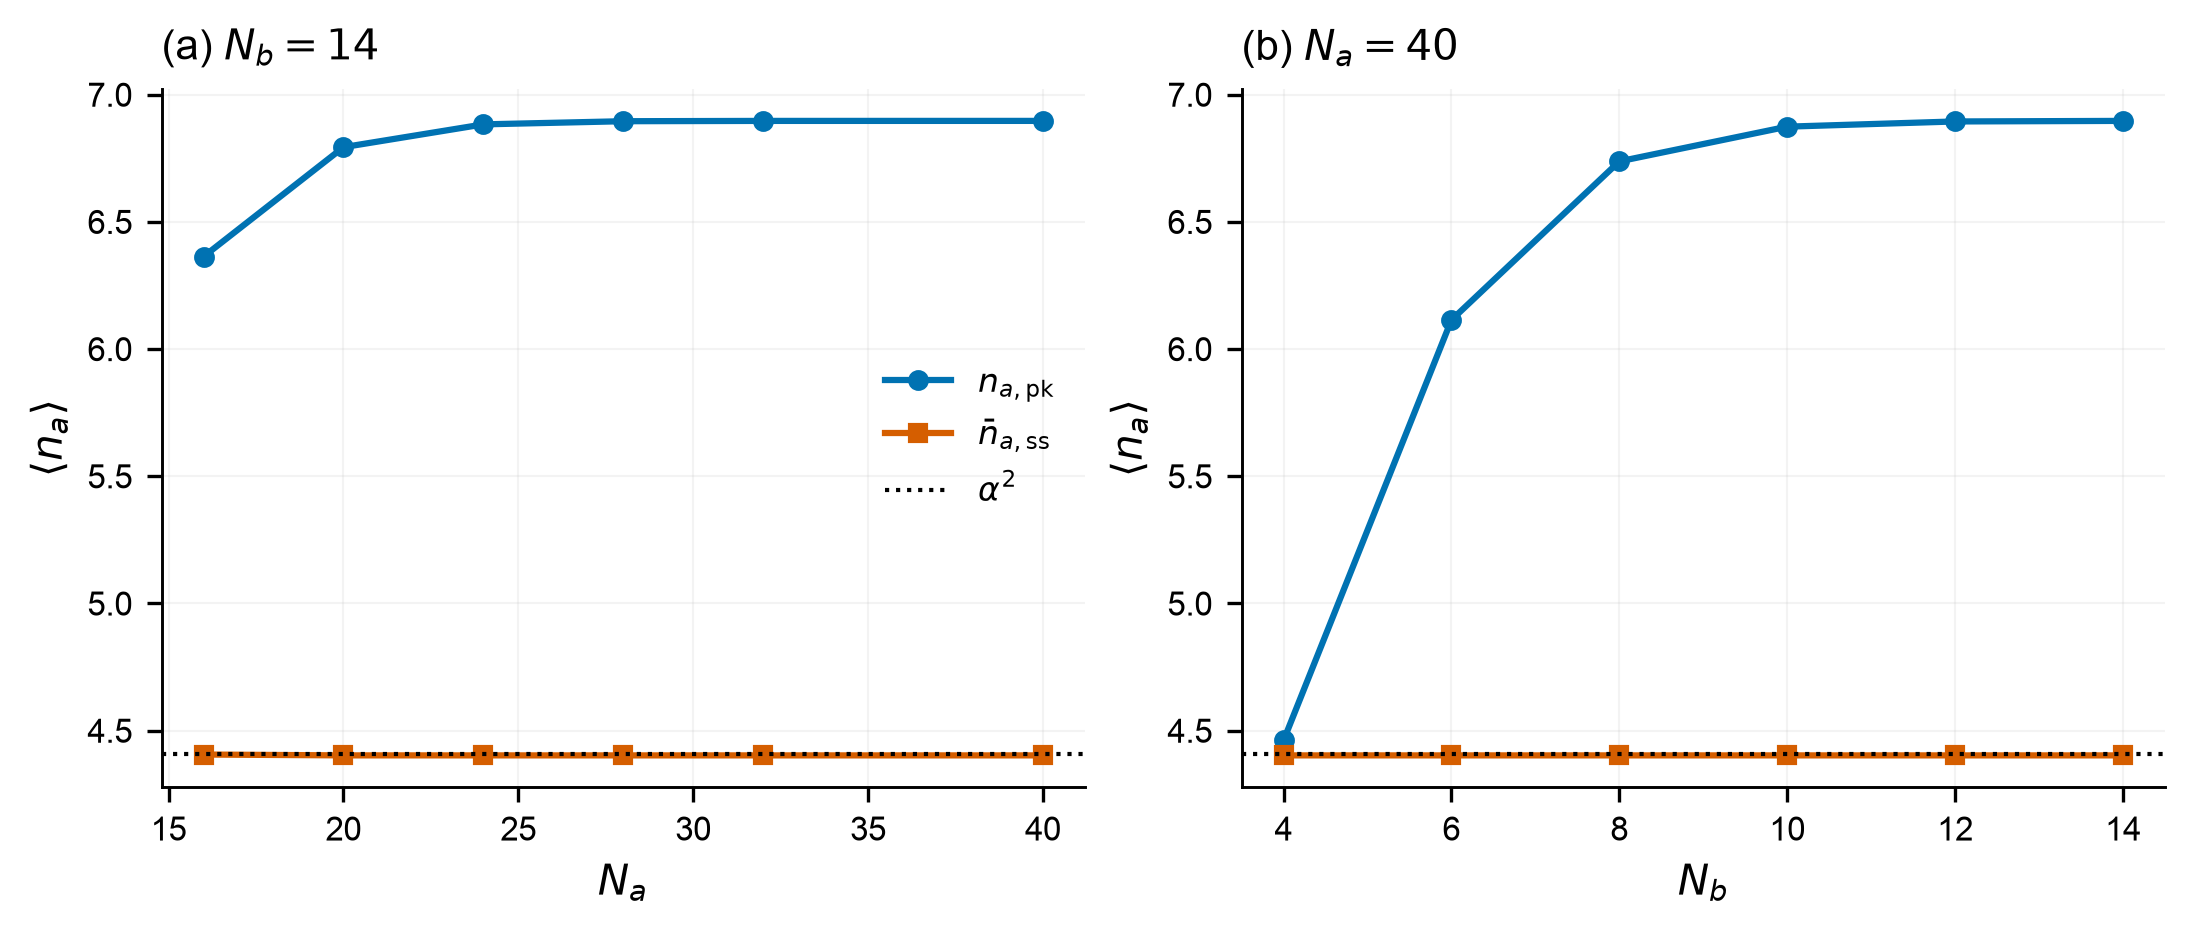

In [5]:
show('task_1_2_convergence', 950)

**Transient and steady occupation versus cutoff.** Peak occupation $n_{a,\mathrm{pk}}=\max_t\langle n_a(t)\rangle$ and late-time mean $\bar n_{a,\mathrm{ss}}$ for (a) varying $N_a$ at $N_b=14$ and (b) varying $N_b$ at $N_a=40$. The steady estimate averages the final 20 saved samples, $t=2.81$–$3$ µs. Dotted lines mark $\alpha^2$. Both sweeps start from vacuum.

## Numerical summaries

In [6]:
import pandas as pd
grid = pd.DataFrame(r['grid'])
print('Maximum memory-state trace distance (%)')
display((100 * grid.pivot(index='Nb', columns='Na', values='max_trace_distance')).round(4))
comparison = pd.DataFrame([r['summary']['selected'], r['summary']['production']],
                          index=['minimum passing', 'chosen cutoff'])
for key in ['max_trace_distance', 'peak_rel_error', 'steady_rel_error', 'max_top2_a', 'max_top_b']:
    comparison[key + '_pct'] = 100 * comparison[key]
display(comparison[['Na', 'Nb', 'max_trace_distance_pct', 'peak_rel_error_pct',
                    'steady_rel_error_pct', 'max_top2_a_pct', 'max_top_b_pct']].round(6))

Maximum memory-state trace distance (%)


Na,16,20,24,28,32,40
Nb,,,,,,
4,39.7324,37.8039,37.7203,37.7187,37.7187,37.7187
6,25.8002,16.4788,14.8325,14.7281,14.7250,14.7250
8,23.7366,9.7814,5.3205,4.6181,4.5725,4.5710
10,23.8494,9.1003,3.0695,1.4254,1.1749,1.1556
12,24.0914,9.1596,2.9482,0.8481,0.3099,0.2225
14,24.1167,9.2109,2.9960,0.8544,0.2064,0.0000


,Na,Nb,max_trace_distance_pct,peak_rel_error_pct,steady_rel_error_pct,max_top2_a_pct,max_top_b_pct
minimum passing,28,12,0.848127,0.042743,0.000002,0.022173,0.018090
chosen cutoff,32,12,0.309932,0.032475,0.000000,0.001362,0.016921


In [7]:
display(pd.DataFrame(r['sweep_Na']).round(6))
display(pd.DataFrame(r['sweep_Nb']).round(6))

,Na,Nb,wall_s,steady_na,peak_na,t_peak_na,peak_nb,max_top2_a,max_top_b,max_trace_distance,t_max_trace_us,peak_rel_error,steady_rel_error
0,16,14,3.42,4.405958,6.363435,0.23,1.994114,0.057084,0.001223,0.241167,0.23,0.077315,0.000759
1,20,14,5.66,4.402654,6.793373,0.23,1.991775,0.012576,0.000463,0.092109,0.23,0.014975,0.000009
2,24,14,8.87,4.402616,6.882972,0.23,1.991568,0.002025,0.000146,0.029960,0.23,0.001983,0.000000
3,28,14,13.32,4.402616,6.895408,0.23,1.991556,0.000253,0.000040,0.008544,0.24,0.000180,0.000000
4,32,14,21.36,4.402616,6.896581,0.23,1.991555,0.000023,0.000019,0.002064,0.24,0.000010,0.000000
5,40,14,43.01,4.402616,6.896651,0.23,1.991555,0.000000,0.000018,0.000000,0.00,0.000000,0.000000


,Na,Nb,wall_s,steady_na,peak_na,t_peak_na,peak_nb,max_top2_a,max_top_b,max_trace_distance,t_max_trace_us,peak_rel_error,steady_rel_error
0,40,4,1.93,4.402631,4.461620,0.55,1.487084,0.0,0.193312,0.377187,0.21,0.353075,0.000003
1,40,6,4.61,4.402614,6.114285,0.23,1.886514,0.0,0.046242,0.147250,0.23,0.113441,0.000000
2,40,8,10.14,4.402615,6.737568,0.23,1.980652,0.0,0.008641,0.045710,0.26,0.023067,0.000000
3,40,10,17.31,4.402615,6.874000,0.23,1.990813,0.0,0.001323,0.011556,0.27,0.003284,0.000000
4,40,12,29.72,4.402616,6.894430,0.23,1.991520,0.0,0.000169,0.002225,0.27,0.000322,0.000000
5,40,14,43.01,4.402616,6.896651,0.23,1.991555,0.0,0.000018,0.000000,0.00,0.000000,0.000000


The cutoff recommendation applies to inflation from vacuum at the supplied parameters. Recheck it for different cat sizes, initial states or drives. Errors are measured at saved times; the displayed contours and finite reference do not establish an exact continuum error bound.